1. Importing necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer

In [2]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
#Load the data
df = pd.read_excel(r"C:\Users\USER\OneDrive\Documents\Decodelabs Project\Data Science decode labs\Dataset for Data Analytics.xlsx")
df

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,ORD201195,2024-06-20,C21126,Desk,1,107.04,392 Main St,Credit Card,Cancelled,TRK38009181,6,FREESHIP,Google,107.04
1196,ORD201196,2024-03-04,C20095,Monitor,2,662.53,778 Main St,Online,Cancelled,TRK69207593,5,NaN,Facebook,1325.06
1197,ORD201197,2023-07-13,C79674,Tablet,2,436.84,275 Main St,Online,Delivered,TRK88039356,2,FREESHIP,Instagram,873.68
1198,ORD201198,2024-08-22,C64753,Chair,4,262.52,509 Main St,Debit Card,Cancelled,TRK71683331,4,WINTER15,Instagram,1050.08


2. Exploratory Data Analysis

In [4]:
print("="*50)
print("BASIC INFO")
print("="*50)
print(f"Shape: {df.shape}")
print(f"\nColumns:\n{df.columns.tolist()}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nFirst 5 rows:")
display(df.head())

BASIC INFO
Shape: (1200, 14)

Columns:
['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice', 'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber', 'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice']

Data Types:
OrderID                       str
Date               datetime64[us]
CustomerID                    str
Product                       str
Quantity                    int64
UnitPrice                 float64
ShippingAddress               str
PaymentMethod                 str
OrderStatus                   str
TrackingNumber                str
ItemsInCart                 int64
CouponCode                    str
ReferralSource                str
TotalPrice                float64
dtype: object

First 5 rows:


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [5]:
print("="*50)
print("MISSING VALUES")
print("="*50)
missing = df.isnull().sum()
# print(missing)
missing_pct = (df.isnull().mean() * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0])

MISSING VALUES
            Missing Count  Missing %
CouponCode            309      25.75


In [6]:
print("="*50)
print("NUMERIC SUMMARY")
print("="*50)
display(df.describe())

print("\n" + "="*50)
print("CATEGORICAL VALUE COUNTS")
print("="*50)
for col in ["Product", "PaymentMethod", "OrderStatus", "CouponCode", "ReferralSource"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

NUMERIC SUMMARY


,Date,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-03-22 16:58:48,2.945833,356.412750,5.485000,1053.968300
min,2023-01-01 00:00:00,1.000000,11.390000,1.000000,11.390000
25%,2023-08-03 18:00:00,2.000000,186.062500,4.000000,410.520000
50%,2024-03-23 00:00:00,3.000000,364.210000,5.000000,823.615000
75%,2024-11-08 12:00:00,4.000000,521.570000,7.000000,1578.475000
max,2025-06-30 00:00:00,5.000000,699.930000,10.000000,3456.400000
std,NaN,1.407557,197.177146,2.281983,819.856558



CATEGORICAL VALUE COUNTS

--- Product ---
Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64

--- PaymentMethod ---
PaymentMethod
Online         258
Cash           246
Credit Card    234
Debit Card     232
Gift Card      230
Name: count, dtype: int64

--- OrderStatus ---
OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64

--- CouponCode ---
CouponCode
FREESHIP    313
NaN         309
WINTER15    292
SAVE10      286
Name: count, dtype: int64

--- ReferralSource ---
ReferralSource
Instagram    259
Email        250
Google       241
Facebook     228
Referral     222
Name: count, dtype: int64


3. Missing Value Treatment

In [7]:
print("Before treating missing values:")
print(df['CouponCode'].value_counts(dropna=False))
print()

# Fill missing CouponCode with a new category "No Coupon" instead of introducing the KNN 
# The KNN is majorly used on numerical dataset, and to that on our coupon column, we will need to encode the it
# Then turn it back to categorical set and this process could introduce artificial patterns and noise
df['CouponCode'] = df['CouponCode'].fillna('No Coupon')

print("After treating missing values:")
print(df['CouponCode'].value_counts(dropna=False))
print()

# Final check
print("Remaining missing values in the whole dataset:")
print(df.isnull().sum().sum())

Before treating missing values:
CouponCode
FREESHIP    313
NaN         309
WINTER15    292
SAVE10      286
Name: count, dtype: int64

After treating missing values:
CouponCode
FREESHIP     313
No Coupon    309
WINTER15     292
SAVE10       286
Name: count, dtype: int64

Remaining missing values in the whole dataset:
0


4. Outlier detection and Neutralization

In [8]:
def detect_outliers_iqr(series):
    """Return lower and upper bounds using IQR method"""
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return lower_bound, upper_bound

# 1. Detecting outliers for TotalPrice and UnitPrice
for col in ['TotalPrice', 'UnitPrice']:
    lower, upper = detect_outliers_iqr(df[col])
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\n{'='*50}")
    print(f"OUTLIERS IN: {col}")
    print(f"{'='*50}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Number of outliers: {len(outliers)}")
    print(f"Percentage of outliers: {(len(outliers)/len(df)*100):.2f}%")


OUTLIERS IN: TotalPrice
Lower bound: -1341.41
Upper bound: 3330.41
Number of outliers: 8
Percentage of outliers: 0.67%

OUTLIERS IN: UnitPrice
Lower bound: -317.20
Upper bound: 1024.83
Number of outliers: 0
Percentage of outliers: 0.00%


In [9]:
# 2. Apply Winsorization (cap the outliers instead of deleting them)
df['TotalPrice_clean'] = df['TotalPrice'].clip(
    lower=detect_outliers_iqr(df['TotalPrice'])[0],
    upper=detect_outliers_iqr(df['TotalPrice'])[1]
)

df['UnitPrice_clean'] = df['UnitPrice'].clip(
    lower=detect_outliers_iqr(df['UnitPrice'])[0],
    upper=detect_outliers_iqr(df['UnitPrice'])[1]
)

print("\n" + "="*50)
print("WINSORIZATION COMPLETED")
print("="*50)
print("New columns created: TotalPrice_clean and UnitPrice_clean")


WINSORIZATION COMPLETED
New columns created: TotalPrice_clean and UnitPrice_clean


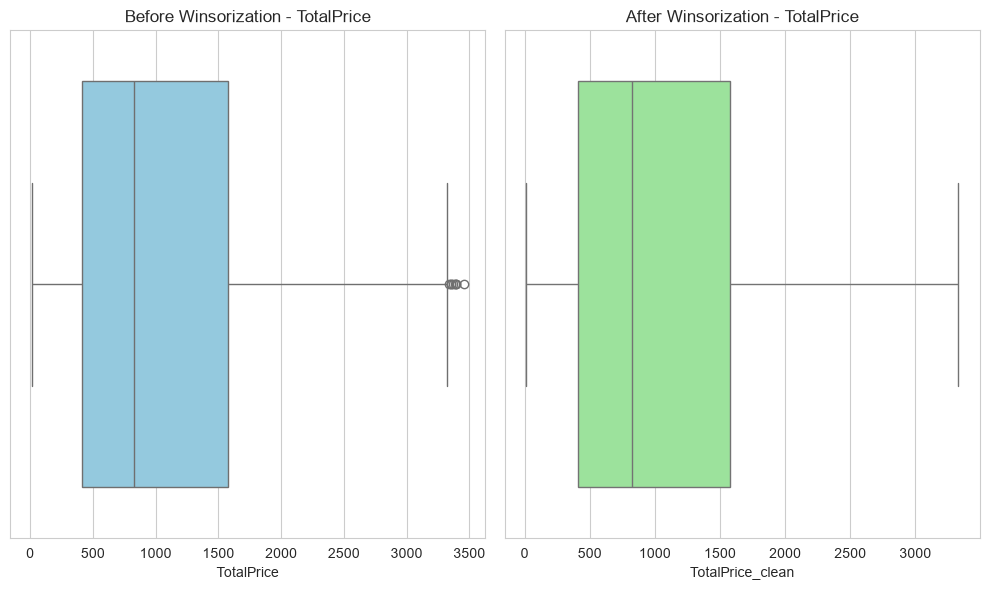

In [11]:
#Before vs After visualozation for TotalPrice

plt.subplot(1,2,1)
sns.boxplot(x=df['TotalPrice'], color='skyblue')
plt.title('Before Winsorization - TotalPrice')

plt.subplot(1,2,2)
sns.boxplot(x=df['TotalPrice_clean'], color='lightgreen')
plt.title('After Winsorization - TotalPrice')

plt.tight_layout()
plt.show()


5. Feature Engineering

In [12]:
# 1. Price per item (normalizes TotalPrice by Quantity)
df['Price_Per_Item'] = df['TotalPrice_clean'] / df['Quantity']

# 2. Cart Utilization (how much of the cart was actually purchased)
df['Cart_Utilization'] = df['Quantity'] / df['ItemsInCart']

# 3. Used Coupon flag (binary feature)
df['Used_Coupon'] = (df['CouponCode'] != 'No Coupon').astype(int)

# 4. High Value Order flag (top 25% of orders)
df['High_Value_Order'] = (df['TotalPrice_clean'] > df['TotalPrice_clean'].quantile(0.75)).astype(int)

# 5. Time-based features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter
df['Is_Weekend'] = df['Date'].dt.dayofweek.isin([5, 6]).astype(int)

# Quick check
print("New features created successfully!")
print(df[['Price_Per_Item', 'Cart_Utilization', 'Used_Coupon', 'High_Value_Order', 'Is_Weekend']].head(10))


New features created successfully!
   Price_Per_Item  Cart_Utilization  Used_Coupon  High_Value_Order  Is_Weekend
0          570.62          0.714286            1                 1           0
1          151.35          0.666667            1                 0           0
2          550.68          0.625000            1                 1           0
3          273.19          0.200000            1                 0           1
4          626.01          0.500000            1                 1           0
5          245.86          0.500000            1                 0           0
6          664.42          0.166667            1                 0           0
7          149.55          0.555556            1                 0           0
8          134.28          1.000000            0                 0           0
9          509.38          0.666667            1                 1           0


6. Final Cleaning, Validation, and Export

In [13]:
# 1. Quick validation
print("="*50)
print("FINAL VALIDATION")
print("="*50)
print(f"Total rows: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"\nMissing values left: {df.isnull().sum().sum()}")

print("\nNew features summary:")
print(df[['Price_Per_Item', 'Cart_Utilization', 'Used_Coupon', 
          'High_Value_Order', 'Is_Weekend']].describe())

# 2. Final column order (clean and organized)
final_columns = [
    # Original identifiers
    'OrderID', 'Date', 'CustomerID', 'Product',
    
    # Original numeric
    'Quantity', 'UnitPrice', 'UnitPrice_clean', 'ItemsInCart',
    'TotalPrice', 'TotalPrice_clean',
    
    # Original categorical
    'ShippingAddress', 'PaymentMethod', 'OrderStatus', 
    'TrackingNumber', 'CouponCode', 'ReferralSource',
    
    # Newly engineered features
    'Price_Per_Item', 'Cart_Utilization', 'Used_Coupon',
    'High_Value_Order', 'Year', 'Month', 'Quarter', 'Is_Weekend'
]

df_clean = df[final_columns].copy()

# 3. Export the clean dataset
df_clean.to_csv("Cleaned_Ecommerce_Orders.csv", index=False)
df_clean.to_excel("Cleaned_Ecommerce_Orders.xlsx", index=False)

print("\n" + "="*50)
print("EXPORT COMPLETE")
print("="*50)
print("Files saved:")
print("→ Cleaned_Ecommerce_Orders.csv")
print("→ Cleaned_Ecommerce_Orders.xlsx")
print(f"\nFinal shape: {df_clean.shape}")


FINAL VALIDATION
Total rows: 1200
Total columns: 24

Missing values left: 0

New features summary:
       Price_Per_Item  Cart_Utilization  Used_Coupon  High_Value_Order  \
count     1200.000000       1200.000000  1200.000000       1200.000000   
mean       356.347727          0.579871     0.742500          0.250000   
std        197.072468          0.249878     0.437439          0.433193   
min         11.390000          0.166667     0.000000          0.000000   
25%        186.062500          0.400000     0.000000          0.000000   
50%        364.210000          0.500000     1.000000          0.000000   
75%        521.570000          0.750000     1.000000          0.250000   
max        699.930000          1.000000     1.000000          1.000000   

        Is_Weekend  
count  1200.000000  
mean      0.298333  
std       0.457717  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       1.000000  
max       1.000000  

EXPORT COMPLETE
Files saved:
→ Cleaned_Ecomm